# MBPO ablation analysis on HalfCheetah-v5

We compare rollout lengths of 1, 5 and 15 steps and replace the baseline ensemble of 7 models
(5 elites) with a single model (1 elite). All ablations use seed 0 and 20 SAC updates per
environment step. The main experiment provides two MBPO seeds and one SAC seed. This notebook
reads saved experiment outputs and runs evaluation episodes in MuJoCo.

To reproduce, start Jupyter from the repository root or its `notebooks/` directory. Install the
repository requirements plus `ipykernel`, and update the two paths below if the archives are stored
elsewhere. The notebook reads archives directly and exports figures and a CSV to `results_ablation/`.

In [1]:
import csv
import io
from pathlib import Path
import sys
from zipfile import ZipFile

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

root = Path.cwd() if (Path.cwd() / "mbpo").is_dir() else Path.cwd().parent
if not (root / "mbpo").is_dir():
    raise FileNotFoundError("Start Jupyter in the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from mbpo.dynamics import ProbabilisticEnsemble
from mbpo.sac import SAC

# Use the archives produced by the main Kaggle run and the ablation run.
MAIN_ARCHIVE = Path.home() / "Downloads" / "mbpo_results.zip"
ABLATION_ARCHIVE = Path.home() / "Downloads" / "mbpo_results(1).zip"
output = root / "results_ablation"
output.mkdir(exist_ok=True)

torch.set_num_threads(1)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## Returns at matched environment steps

Each point is the mean return of five deterministic evaluation episodes recorded during training.
The MBPO baseline band and table show the mean ± sample SD across its two seeds. Each other setting
has one seed. The ablations share seed 0 with the main run, so the table includes that baseline seed
separately. The 60k bars use the same logged metric as the curves,
so each bar rests on a single evaluation per seed.

In [2]:
def read_progress(archive, run):
    with ZipFile(archive) as bundle, bundle.open(f"runs/{run}/progress.csv") as stream:
        rows = csv.DictReader(io.TextIOWrapper(stream, encoding="utf-8"))
        return {int(row["env_steps"]): float(row["eval_return"])
                for row in rows if int(row["env_steps"]) <= 60_000}

groups = {
    "MBPO baseline": (MAIN_ARCHIVE, ("mbpo_seed0", "mbpo_seed1"), "#2563eb"),
    "SAC baseline": (MAIN_ARCHIVE, ("sac_seed0",), "#64748b"),
    "k=5": (ABLATION_ARCHIVE, ("mbpo_k5_seed0",), "#15803d"),
    "k=15": (ABLATION_ARCHIVE, ("mbpo_k15_seed0",), "#c2410c"),
    "One model": (ABLATION_ARCHIVE, ("mbpo_ens1_seed0",), "#7e22ce"),
}
curves = {}
for label, (archive, runs, color) in groups.items():
    logs = [read_progress(archive, run) for run in runs]
    steps = np.array(sorted(set.intersection(*(set(log) for log in logs))))
    if not {30_000, 60_000}.issubset(steps):
        raise ValueError(f"{label} is missing a 30k or 60k evaluation.")
    curves[label] = (steps, np.array([[log[step] for step in steps] for log in logs]), color)

def summarize(label, steps, scores):
    at_30k = scores[:, steps == 30_000].ravel()
    at_60k = scores[:, steps == 60_000].ravel()
    return {
        "configuration": label, "seeds": len(scores),
        "return_30k": at_30k.mean(), "sd_30k": at_30k.std(ddof=1) if len(scores) > 1 else None,
        "return_60k": at_60k.mean(), "sd_60k": at_60k.std(ddof=1) if len(scores) > 1 else None,
    }

summary = [summarize(label, steps, scores) for label, (steps, scores, _) in curves.items()]
base_steps, base_scores, _ = curves["MBPO baseline"]
summary.insert(1, summarize("MBPO baseline (seed 0)", base_steps, base_scores[:1]))

with (output / "returns_30k_60k.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

def format_return(mean, sd):
    return f"{mean:,.0f}" if sd is None else f"{mean:,.0f} ± {sd:,.0f}"

table = ["| Configuration | Seeds | Return at 30k | Return at 60k |", "|---|---:|---:|---:|"]
for row in summary:
    at_30k = format_return(row["return_30k"], row["sd_30k"])
    at_60k = format_return(row["return_60k"], row["sd_60k"])
    table.append(f"| {row['configuration']} | {row['seeds']} | {at_30k} | {at_60k} |")
display(Markdown("\n".join(table)))

| Configuration | Seeds | Return at 30k | Return at 60k |
|---|---:|---:|---:|
| MBPO baseline | 2 | 5,125 ± 1,683 | 7,036 ± 1,362 |
| MBPO baseline (seed 0) | 1 | 3,935 | 6,073 |
| SAC baseline | 1 | 436 | 2,629 |
| k=5 | 1 | 6,427 | 8,952 |
| k=15 | 1 | 6,825 | 5,899 |
| One model | 1 | 5,970 | 6,952 |

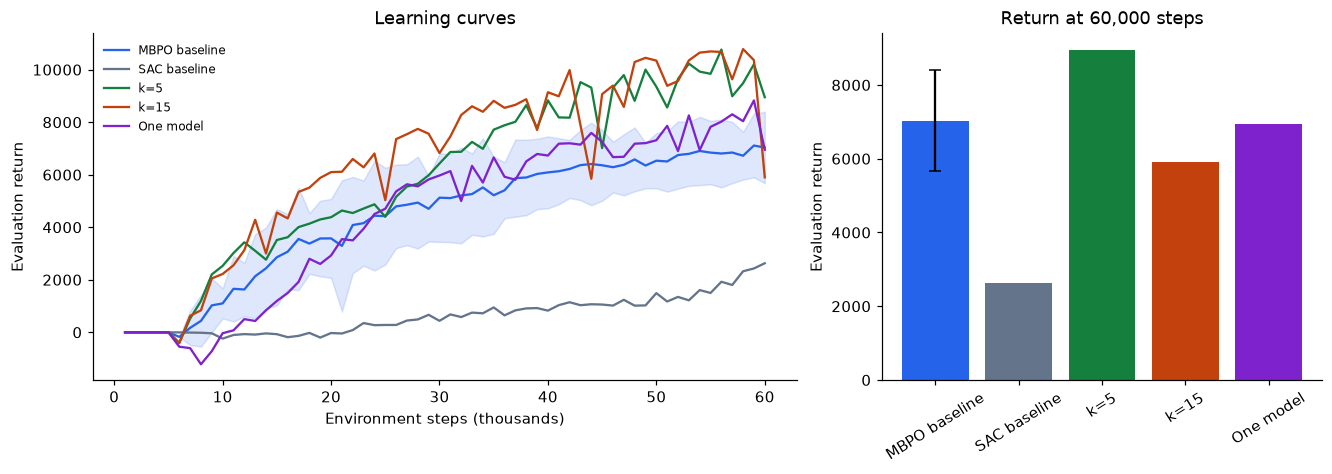

In [3]:
fig, (ax, bar_ax) = plt.subplots(1, 2, figsize=(12, 4.2), width_ratios=(1.6, 1),
                                 layout="constrained")
for label, (steps, scores, color) in curves.items():
    mean = scores.mean(axis=0)
    ax.plot(steps / 1_000, mean, color=color, label=label)
    if len(scores) > 1:
        sd = scores.std(axis=0, ddof=1)
        ax.fill_between(steps / 1_000, mean - sd, mean + sd, color=color, alpha=0.15)
ax.set(title="Learning curves", xlabel="Environment steps (thousands)", ylabel="Evaluation return")
ax.legend(frameon=False, fontsize=8)

for index, (label, (steps, scores, color)) in enumerate(curves.items()):
    final = scores[:, steps == 60_000].ravel()
    sd = final.std(ddof=1) if len(final) > 1 else None
    bar_ax.bar(index, final.mean(), color=color, yerr=sd, capsize=4)
bar_ax.set(title="Return at 60,000 steps", ylabel="Evaluation return",
           xticks=range(len(curves)), xticklabels=list(curves))
bar_ax.tick_params(axis="x", labelrotation=32)
fig.savefig(output / "ablation_returns.png", dpi=180)
plt.show()

**Rollout length 5.** With the horizon increased from one to five steps, seed 0 reached 8,952
at 60k compared with 6,073 for the matched baseline. Over the last five evaluations (56k–60k) it
averaged 9,680, above both k = 1 seeds (6,064 and 7,745). A second seed would help test its
reliability.

**Rollout length 15.** With 15-step rollouts the run was ahead of the matched baseline at 30k
(6,825 vs 3,935). Its single evaluation at 60k is lower (5,899 vs 6,073), but that evaluation has a
standard deviation of 4,004 across its five episodes, and the nine evaluations before it lie between
9,386 and 10,784. The 60k bar therefore understates this run: over the last five evaluations it
averaged 9,471, close to k = 5. The horizon test below measures whether prediction error accumulates
under fixed actions.

**Model buffer.** The model buffer held 400,000 transitions in every run. For k = 1 this covers the
last four rollouts. For k = 5 and k = 15 it keeps only steps 2–5 and 12–15 of the latest rollout, so
these runs differ from the baseline in more than k and do not isolate the effect of rollout length.

**One model.** With one model and one elite, there is no between-model disagreement signal.
Its 60k return (6,952) sits between the two baseline returns (6,073 and 7,999), and its average over
the last five evaluations (8,028) is slightly above both baseline seeds (6,064 and 7,745). The seeds
differ by more than that margin, so these runs leave the ensemble's effect on return unresolved.

## Open-loop model error by horizon

We evaluate the seed 0 models saved at 25k, 100k and the end of training. The final seed 0
policy collects fresh deterministic evaluation episodes in MuJoCo. All three models start from
the same real observations and replay the same recorded actions for 30 steps, feeding their own
predicted states back at each step. Windows stay inside a single episode.

We propagate the mean prediction across the saved elites. Observation error is RMSE after
scaling each coordinate by its standard deviation over the real evaluation observations
(coordinates with negligible variation are excluded). Reward error is per-step RMSE rather
than cumulative return error. Disagreement is measured across elite predictions at the same
model input, in the same normalized state units. These checkpoints are tested on trajectories
from the final policy, which may visit states that earlier checkpoints saw infrequently.

In [4]:
RUN = "mbpo_seed0"

def load_checkpoint(filename):
    with ZipFile(MAIN_ARCHIVE) as bundle:
        data = bundle.read(f"runs/{RUN}/{filename}")
    return torch.load(io.BytesIO(data), map_location="cpu", weights_only=True)

def load_policy(checkpoint):
    cfg = checkpoint["config"]
    policy = SAC(checkpoint["obs_dim"], checkpoint["act_dim"], torch.device("cpu"),
                 hidden_dim=cfg["hidden_dim"], gamma=cfg["gamma"])
    policy.load_state_dict(checkpoint["agent"])
    policy.actor.eval()
    policy.critic.eval()
    return policy

def load_model(checkpoint):
    cfg = checkpoint["config"]
    model = ProbabilisticEnsemble(
        checkpoint["obs_dim"], checkpoint["act_dim"], ensemble_size=cfg["ensemble_size"],
        num_elites=cfg["num_elites"], hidden_dim=cfg["model_hidden_dim"],
        num_layers=cfg["model_num_layers"], weight_decay=cfg["model_weight_decay"],
    )
    model.load_state_dict(checkpoint["model"])
    model.scaler.mu, model.scaler.std = checkpoint["model_scaler"]
    model.elites = checkpoint["model_elites"]
    return model.eval()

final_checkpoint = load_checkpoint("final.pt")
policy = load_policy(final_checkpoint)
ENV_ID = final_checkpoint["config"]["env_id"]
HORIZON = 30

def collect_trajectories(episode_seeds):
    env = gym.make(ENV_ID)
    trajectories = []
    try:
        for seed in episode_seeds:
            obs, _ = env.reset(seed=seed)
            observations, actions, rewards = [obs], [], []
            while True:
                action = policy.act(obs, deterministic=True)
                obs, reward, terminated, truncated, _ = env.step(action)
                observations.append(obs)
                actions.append(action)
                rewards.append(reward)
                if terminated or truncated:
                    break
            trajectories.append(tuple(np.asarray(x, dtype=np.float32)
                                      for x in (observations, actions, rewards)))
    finally:
        env.close()
    return trajectories

trajectories = collect_trajectories(range(31000, 31012))
windows = [(obs[i:i + HORIZON + 1], act[i:i + HORIZON], rew[i:i + HORIZON])
           for obs, act, rew in trajectories for i in range(0, len(act) - HORIZON + 1, HORIZON)]
real_obs, real_act, real_rew = (torch.from_numpy(np.stack(values)) for values in zip(*windows))
state_scale = torch.from_numpy(np.concatenate([obs for obs, _, _ in trajectories])).std(0)
active = state_scale > 1e-6
print(f"Open-loop evaluation uses {len(windows)} windows from {len(trajectories)} episodes "
      f"and {active.sum().item()} observation coordinates.")

Open-loop evaluation uses 396 windows from 12 episodes and 17 observation coordinates.


25k | state RMSE h=1: 0.435 / h=30: 7.324 | reward RMSE h=1: 0.55 / h=30: 9.14
100k | state RMSE h=1: 0.115 / h=30: 6.890 | reward RMSE h=1: 0.22 / h=30: 9.46
Final (200k) | state RMSE h=1: 0.075 / h=30: 6.625 | reward RMSE h=1: 0.04 / h=30: 28.08


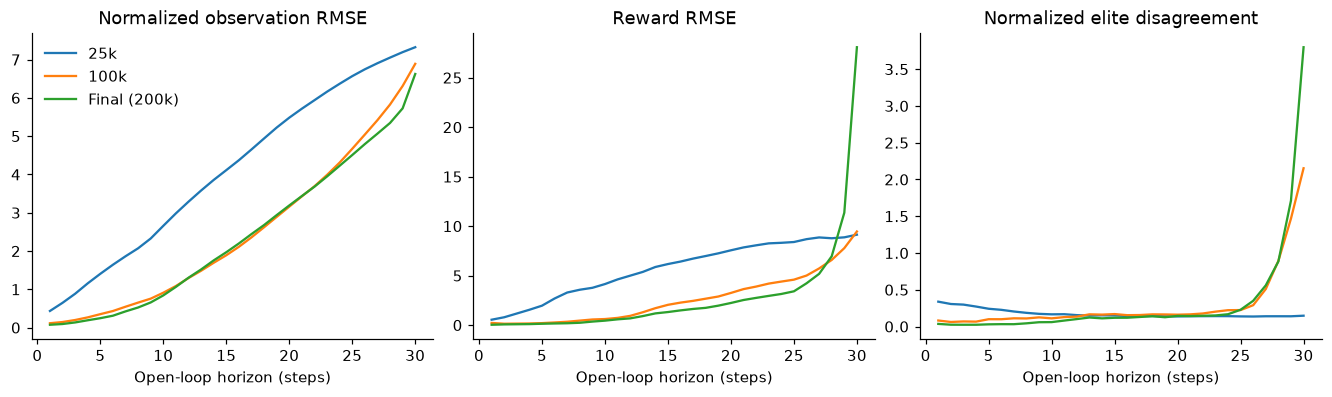

In [5]:
@torch.no_grad()
def measure_horizon(model):
    obs = real_obs[:, 0]
    errors = []
    for h in range(HORIZON):
        means, _ = model._predict_all(obs, real_act[:, h])
        elites = means[model.elites]
        prediction = elites.mean(0)
        obs = obs + prediction[:, 1:]
        state_error = (obs[:, active] - real_obs[:, h + 1, active]) / state_scale[active]
        reward_error = prediction[:, 0] - real_rew[:, h]
        disagreement = elites[:, :, 1:][:, :, active].std(0, unbiased=False) / state_scale[active]
        errors.append([state_error.square().mean().sqrt().item(),
                       reward_error.square().mean().sqrt().item(),
                       disagreement.square().mean().sqrt().item()])
    return np.asarray(errors)

checkpoints = {
    "25k": load_checkpoint("snapshots/step_025000.pt"),
    "100k": load_checkpoint("snapshots/step_100000.pt"),
    f"Final ({final_checkpoint['env_steps'] // 1_000}k)": final_checkpoint,
}
horizon_results = {label: measure_horizon(load_model(checkpoint))
                   for label, checkpoint in checkpoints.items()}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for label, values in horizon_results.items():
    for axis, column in zip(axes, values.T):
        axis.plot(np.arange(1, HORIZON + 1), column, label=label)
    print(f"{label} | state RMSE h=1: {values[0, 0]:.3f} / h=30: {values[-1, 0]:.3f} "
          f"| reward RMSE h=1: {values[0, 1]:.2f} / h=30: {values[-1, 1]:.2f}")
for axis, title in zip(axes, ("Normalized observation RMSE", "Reward RMSE", "Normalized elite disagreement")):
    axis.set(title=title, xlabel="Open-loop horizon (steps)")
axes[0].legend(frameon=False)
fig.savefig(output / "model_error_by_horizon.png", dpi=180)
plt.show()

In [6]:
final_error = list(horizon_results.values())[-1]
short, long = final_error[[0, -1], 0]
direction = "rose" if long > short else "fell" if long < short else "was unchanged"
display(Markdown(
    f"For the final model, normalized observation RMSE **{direction}** from **{short:.3f}** "
    f"at one step to **{long:.3f}** at 30 steps on the same action sequences. "
    "This measures open-loop error in the main run. Connecting the return gap to model error "
    "would require further evidence from the ablation runs."
))

For the final model, normalized observation RMSE **rose** from **0.075** at one step to **6.625** at 30 steps on the same action sequences. This measures open-loop error in the main run. Connecting the return gap to model error would require further evidence from the ablation runs.

## Critic calibration at initial states

We reload the final MBPO policy and critic from seed 0 and evaluate on 32 new reset seeds.
For each initial observation and action we use the smaller of the two critic estimates.
The first panel compares it with the deterministic policy's discounted environment rewards.
The second uses sampled policy actions and the SAC soft return, which adds
`−alpha × log π(aₜ | sₜ)` to rewards from the second step onward because Q conditions
on the first action. Both Monte Carlo returns stop at the environment time limit.
Each point is a single trajectory, so scatter includes trajectory variance.

Deterministic policy / reward return | mean Q − return: -209.5 | MAE: 209.5
Stochastic policy / SAC soft return | mean Q − return: -44.5 | MAE: 44.5


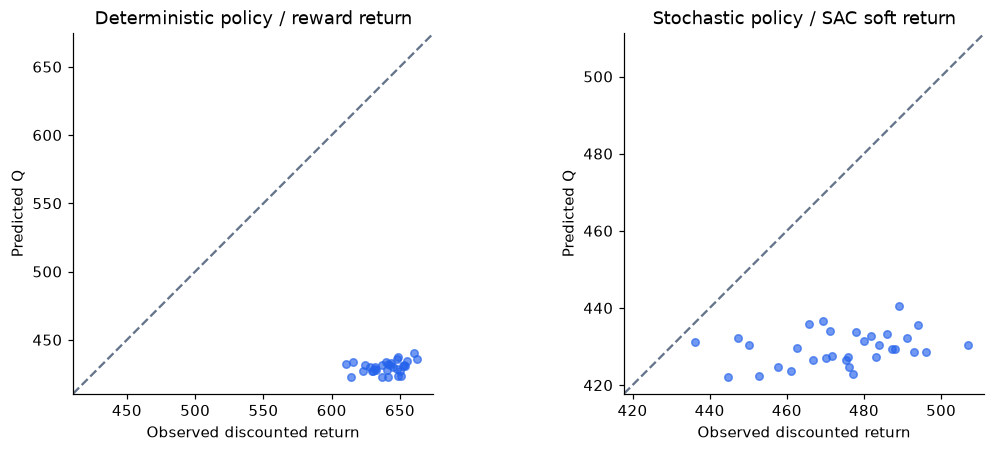

Across these reset seeds, the critic was **44.5** points **below** the soft Monte Carlo return on average. The deterministic comparison is supplementary because it changes the evaluation policy and drops the entropy term.

In [7]:
@torch.no_grad()
def measure_calibration(episode_seeds, stochastic):
    env = gym.make(ENV_ID)
    results = []
    alpha = policy.alpha.item()
    try:
        for seed in episode_seeds:
            torch.manual_seed(seed)
            obs, _ = env.reset(seed=seed)
            discount, observed = 1.0, 0.0
            initial_q = None
            while True:
                state = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
                action, log_prob = policy.actor(
                    state, deterministic=not stochastic, with_log_prob=stochastic,
                )
                entropy_reward = 0.0
                if initial_q is None:
                    initial_q = policy.critic(state, action).min().item()
                elif stochastic:
                    entropy_reward = -alpha * log_prob.item()
                obs, reward, terminated, truncated, _ = env.step(action[0].numpy())
                observed += discount * (reward + entropy_reward)
                discount *= policy.gamma
                if terminated or truncated:
                    break
            results.append((initial_q, observed))
    finally:
        env.close()
    return np.asarray(results)

seeds = range(32000, 32032)
calibrations = {
    "Deterministic policy / reward return": measure_calibration(seeds, stochastic=False),
    "Stochastic policy / SAC soft return": measure_calibration(seeds, stochastic=True),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for axis, (label, values) in zip(axes, calibrations.items()):
    predicted, observed = values.T
    bias = (predicted - observed).mean()
    mae = np.abs(predicted - observed).mean()
    low, high = values.min(), values.max()
    padding = max((high - low) * 0.05, 1)
    limits = (low - padding, high + padding)
    axis.plot(limits, limits, color="#64748b", linestyle="--")
    axis.scatter(observed, predicted, color="#2563eb", alpha=0.65, s=24)
    axis.set(title=label, xlabel="Observed discounted return", ylabel="Predicted Q",
             xlim=limits, ylim=limits, aspect="equal")
    print(f"{label} | mean Q − return: {bias:+.1f} | MAE: {mae:.1f}")
fig.savefig(output / "critic_calibration.png", dpi=180)
plt.show()

soft_values = calibrations["Stochastic policy / SAC soft return"]
soft_bias = (soft_values[:, 0] - soft_values[:, 1]).mean()
direction = "above" if soft_bias >= 0 else "below"
display(Markdown(
    f"Across these reset seeds, the critic was **{abs(soft_bias):.1f}** points **{direction}** "
    "the soft Monte Carlo return on average. The deterministic comparison is supplementary "
    "because it changes the evaluation policy and drops the entropy term."
))